# Spotify Tracks · Predicción de popularidad con XGBoost
**MLY1101 – Machine Learning · Evaluación Parcial N°2 (Caso C)**

Este notebook sigue las etapas de CRISP-DM y reproduce lo descrito en el `README.md`:
1. Problema de negocio y KPIs
2. Carga de datos y target
3. Análisis exploratorio (EDA)
4. Preparación de datos
5. Modelado con XGBoost (clasificación y regresión)
6. Interpretación de resultados

**Cómo ejecutarlo:** instalar `requirements.txt` y correr todas las celdas en orden (*Run All*).

## 1. Problema de negocio

Las plataformas y sellos musicales deben decidir qué canciones promocionar, pero hoy lo hacen con criterio subjetivo.
**Problema:** clasificar si una canción será popular (`popularity > 70`) usando sus características de audio, duración, si es explícita y su género.
**Uso esperado:** el modelo entrega un ranking de candidatas para apoyar al equipo de promoción, no reemplaza su decisión.

## 2. KPIs

| Tipo | KPI | Qué mide |
|---|---|---|
| Clasificación (principal) | **F1-score** | Equilibrio entre Precision y Recall en la clase "popular" |
| Clasificación | **Precision** | De las canciones que el modelo marca como populares, cuántas realmente lo son |
| Clasificación | **Recall** | De las canciones realmente populares, cuántas logra detectar |
| Clasificación (apoyo) | **PR-AUC** | Calidad del ranking sin depender del umbral |
| Regresión | **MAE / RMSE** | Error promedio (y error con castigo a los grandes) en puntos de popularidad |

No usamos *accuracy*: solo ~4 % de las canciones es popular, así que predecir "nadie es popular" ya daría ~96 % sin ser útil.

In [1]:
# Librerías del proyecto (si falta alguna: pip install -r requirements.txt)
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error)
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Parámetros globales: semilla (reproducibilidad) y umbral de popularidad
SEED = 42
THRESHOLD_POPULAR = 70

# Rutas del proyecto: el notebook vive en notebooks/, los datos en data/
BASE = Path("..") if Path("../data").exists() else Path(".")
DATA_PATH = BASE / "data" / "Spotify_Tracks_Dataset.csv"
IMG_DIR, MODELS_DIR = BASE / "images", BASE / "models"
IMG_DIR.mkdir(exist_ok=True); MODELS_DIR.mkdir(exist_ok=True)

## 3. Carga de datos y target

Dataset público *Spotify Tracks* con 114.000 filas y 21 columnas (audio, duración, género, popularidad).
El target `is_popular` vale 1 si `popularity > 70` y 0 en otro caso.

In [2]:
# Carga el CSV y crea el target binario is_popular (1 = popularity > 70)
df = pd.read_csv(DATA_PATH)
df["is_popular"] = (df["popularity"] > THRESHOLD_POPULAR).astype(int)

# Resumen general y desbalance de clases
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
print(f"Canciones populares (popularity > {THRESHOLD_POPULAR}): {df['is_popular'].sum():,} ({df['is_popular'].mean():.2%})")
print(f"Baseline 'nadie es popular' -> accuracy = {1 - df['is_popular'].mean():.2%}")
df.head()

Filas: 114,000 | Columnas: 22
Canciones populares (popularity > 70): 4,846 (4.25%)
Baseline 'nadie es popular' -> accuracy = 95.75%


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,is_popular
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,1
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,0
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,0
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,1
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,1


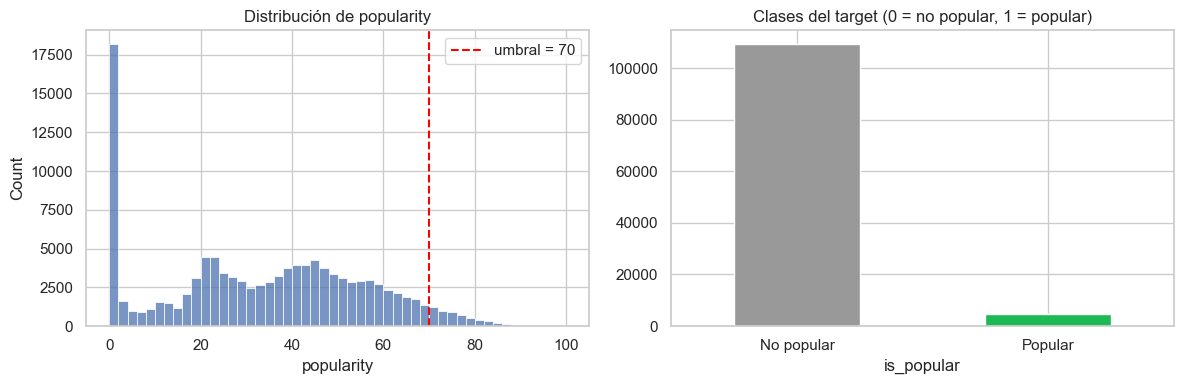

In [3]:
# Gráfico 1: distribución de popularity (con el umbral) y balance de clases del target
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["popularity"], bins=50, ax=ax[0])
ax[0].axvline(THRESHOLD_POPULAR, color="red", ls="--", label=f"umbral = {THRESHOLD_POPULAR}")
ax[0].set_title("Distribución de popularity"); ax[0].legend()
df["is_popular"].value_counts().sort_index().plot.bar(ax=ax[1], color=["#999", "#1DB954"])
ax[1].set_title("Clases del target (0 = no popular, 1 = popular)")
ax[1].set_xticklabels(["No popular", "Popular"], rotation=0)
plt.tight_layout(); plt.savefig(IMG_DIR / "01_target.png", dpi=120); plt.show()

## 4. Análisis exploratorio (EDA)

### 4.1 Calidad de datos
Revisamos nulos, valores en cero que parecen errores y canciones repetidas.
Lo clave: una misma canción puede aparecer en varios géneros (mismo `track_id`), lo que obliga a separar train/test por canción.

In [4]:
# Calidad de datos: nulos, ceros sospechosos y canciones repetidas
nulos = df.isna().sum()
print("Columnas con nulos:\n", nulos[nulos > 0], "\n")

print("Valores en cero que podrían ser errores o datos faltantes:")
print(f"  popularity == 0     : {(df['popularity'] == 0).sum():,} ({(df['popularity'] == 0).mean():.1%})")
print(f"  tempo == 0          : {(df['tempo'] == 0).sum():,}")
print(f"  time_signature == 0 : {(df['time_signature'] == 0).sum():,}")
print(f"  duration_ms == 0    : {(df['duration_ms'] == 0).sum():,}\n")

# Canciones repetidas (riesgo de fuga de datos si el split fuera aleatorio)
n_dup_rows = df["track_id"].duplicated(keep=False).sum()
print(f"Filas cuyo track_id aparece más de una vez: {n_dup_rows:,} ({n_dup_rows/len(df):.1%})")
print(f"Tracks únicos: {df['track_id'].nunique():,} de {len(df):,} filas")
print(f"Tracks únicos populares: {df.loc[df.is_popular == 1, 'track_id'].nunique():,} vs filas populares: {df['is_popular'].sum():,}")
print(f"Géneros: {df['track_genre'].nunique()} | filas por género (min-max): {df['track_genre'].value_counts().min()}-{df['track_genre'].value_counts().max()}")

Columnas con nulos:
 artists       1
album_name    1
track_name    1
dtype: int64 

Valores en cero que podrían ser errores o datos faltantes:
  popularity == 0     : 16,020 (14.1%)
  tempo == 0          : 157
  time_signature == 0 : 163
  duration_ms == 0    : 1

Filas cuyo track_id aparece más de una vez: 40,900 (35.9%)
Tracks únicos: 89,741 de 114,000 filas
Tracks únicos populares: 2,734 vs filas populares: 4,846
Géneros: 114 | filas por género (min-max): 1000-1000


### 4.2 Ceros en `popularity` por género
Los ceros se concentran en ciertos géneros (jazz, iranian, romance, soul, latin, country). Es poco probable que sean canciones realmente sin oyentes:
podrían ser datos sin puntuar. Los mantenemos, pero lo declaramos como limitación del target.

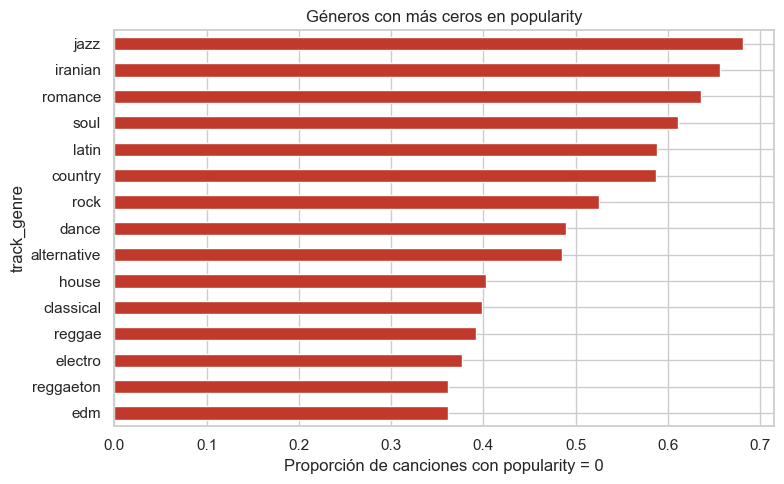

In [5]:
# Gráfico 2: porcentaje de canciones con popularity = 0 en los 15 géneros más afectados
ceros = (df["popularity"] == 0).groupby(df["track_genre"]).mean().sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
ceros.sort_values().plot.barh(color="#c0392b")
plt.xlabel("Proporción de canciones con popularity = 0"); plt.title("Géneros con más ceros en popularity")
plt.tight_layout(); plt.savefig(IMG_DIR / "02_ceros_por_genero.png", dpi=120); plt.show()

### 4.3 Variables de audio vs. popularidad
Las canciones populares son algo más fuertes (`loudness`) y bailables, y menos acústicas e instrumentales.
Pero las diferencias son pequeñas y ninguna correlación (Spearman) supera |0,08|: ninguna variable sola predice bien la popularidad.

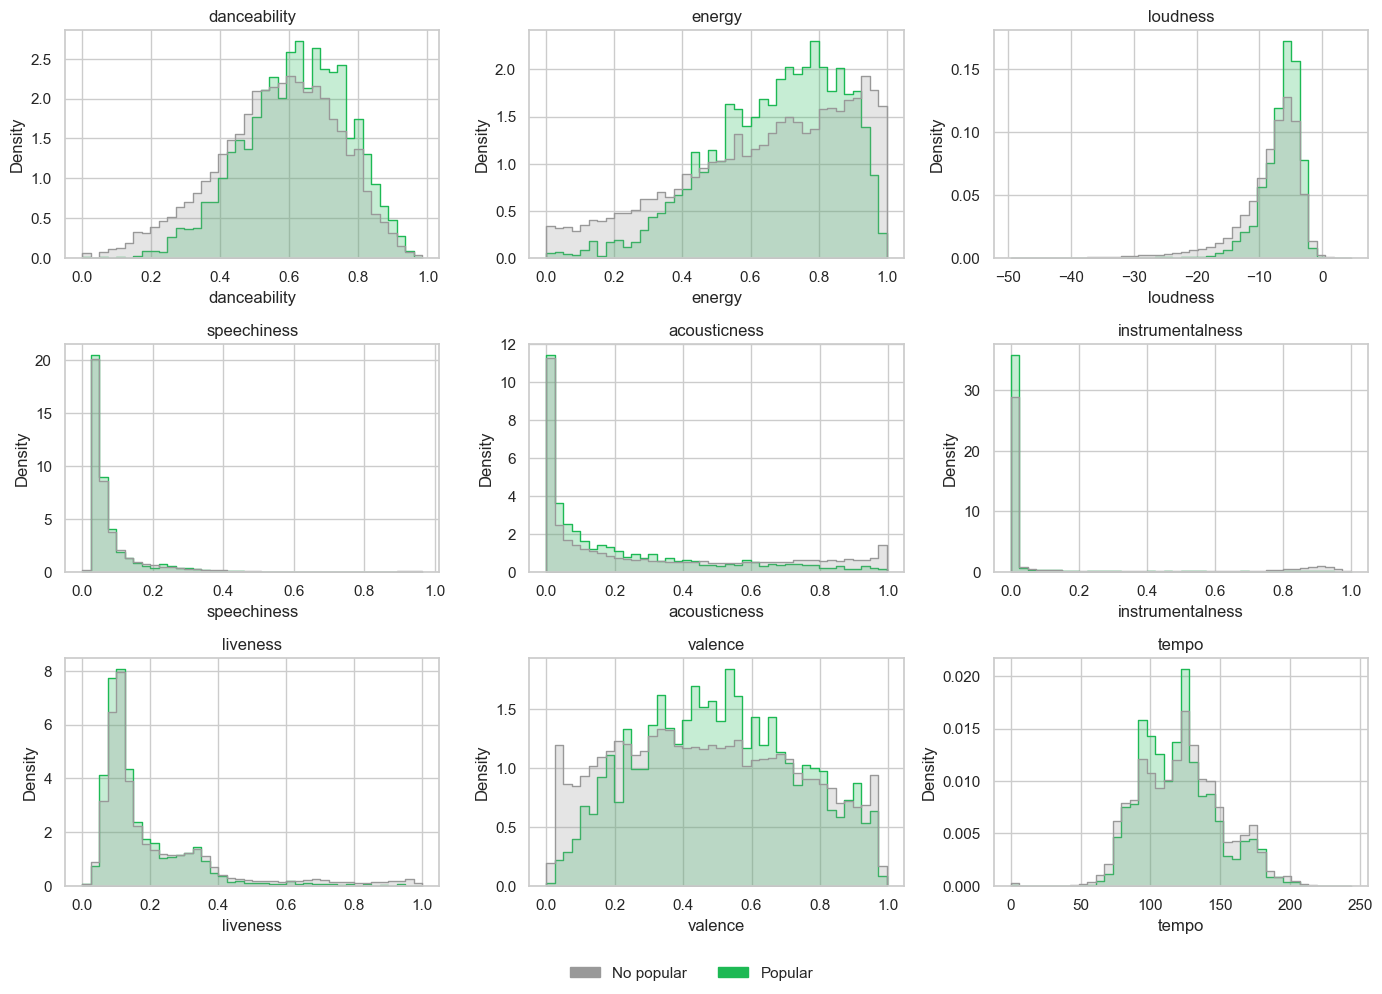

is_popular,0,1
danceability,0.564,0.619
energy,0.640,0.675
loudness,-8.334,-6.561
speechiness,0.085,0.076
acousticness,0.319,0.217
instrumentalness,0.161,0.035
liveness,0.215,0.171
valence,0.473,0.505
tempo,122.244,119.978


In [6]:
# Gráfico 3: distribución de cada variable de audio, separando populares y no populares
audio_cols = ["danceability", "energy", "loudness", "speechiness", "acousticness",
              "instrumentalness", "liveness", "valence", "tempo"]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), audio_cols):
    sns.histplot(data=df, x=col, hue="is_popular", stat="density", common_norm=False,
                 element="step", bins=40, palette=["#999", "#1DB954"], ax=ax, legend=False)
    ax.set_title(col)
# Leyenda manual (colores fijos: gris = no popular, verde = popular)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color="#999", label="No popular"), Patch(color="#1DB954", label="Popular")],
           loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1]); plt.savefig(IMG_DIR / "03_audio_por_clase.png", dpi=120); plt.show()

# Medias por clase para comparar numéricamente
df.groupby("is_popular")[audio_cols].mean().T.round(3)

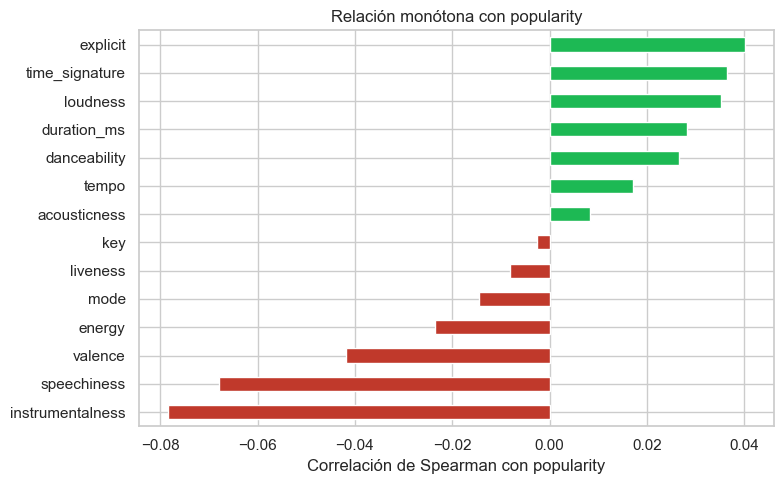

In [7]:
# Gráfico 4: correlación de Spearman de cada variable con popularity
num_cols = audio_cols + ["duration_ms", "key", "mode", "time_signature"]
tmp = df[num_cols].copy(); tmp["explicit"] = df["explicit"].astype(int)
corr = tmp.corrwith(df["popularity"], method="spearman").sort_values()
plt.figure(figsize=(8, 5))
corr.plot.barh(color=["#c0392b" if v < 0 else "#1DB954" for v in corr])
plt.xlabel("Correlación de Spearman con popularity"); plt.title("Relación monótona con popularity")
plt.tight_layout(); plt.savefig(IMG_DIR / "04_correlacion.png", dpi=120); plt.show()

### 4.4 Género y contenido explícito
El género es la variable más informativa: `pop` tiene 28 % de canciones populares y 26 de los 114 géneros no tienen ninguna.
Las canciones explícitas son populares el doble de veces (8,5 % vs 3,9 %).

Géneros sin ninguna canción popular: 26 de 114


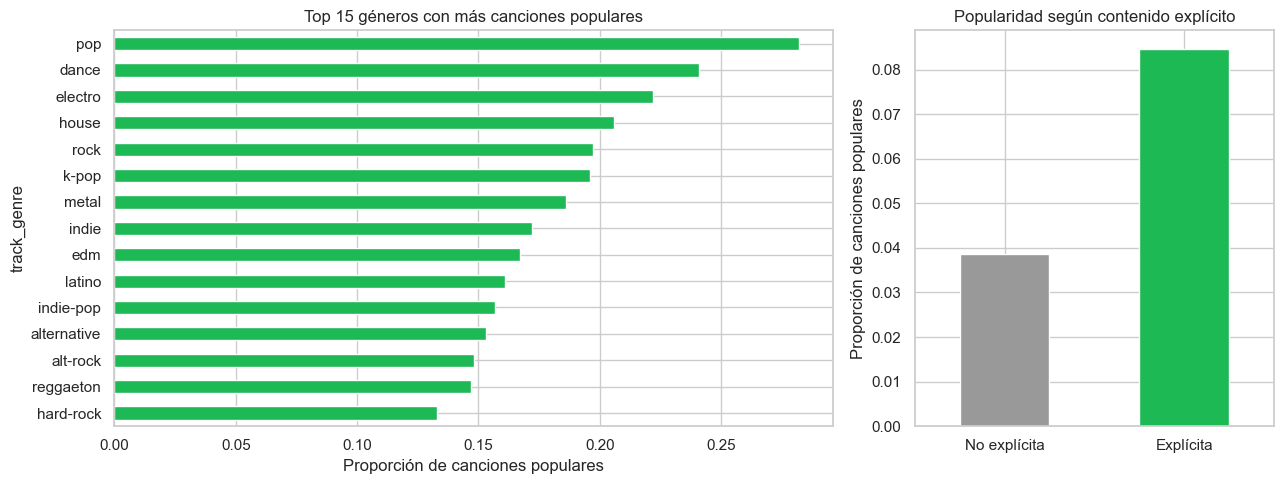

In [8]:
# Gráfico 5: % de canciones populares por género (top 15) y por contenido explícito
por_genero = df.groupby("track_genre")["is_popular"].mean().sort_values(ascending=False)
print(f"Géneros sin ninguna canción popular: {(por_genero == 0).sum()} de {len(por_genero)}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 1]})
por_genero.head(15).sort_values().plot.barh(ax=ax[0], color="#1DB954")
ax[0].set_xlabel("Proporción de canciones populares"); ax[0].set_title("Top 15 géneros con más canciones populares")
df.groupby("explicit")["is_popular"].mean().rename({False: "No explícita", True: "Explícita"}).plot.bar(ax=ax[1], color=["#999", "#1DB954"])
ax[1].set_ylabel("Proporción de canciones populares"); ax[1].set_xlabel(""); ax[1].set_title("Popularidad según contenido explícito")
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=0)
plt.tight_layout(); plt.savefig(IMG_DIR / "05_popular_por_genero.png", dpi=120); plt.show()

## 5. Preparación de datos

- **Se descartan** identificadores y texto (`track_id`, nombres, álbum, `artists`): `artists` haría que el modelo aprenda *quién* es famoso, no *qué* hace popular a una canción.
- **Se usan** 9 variables de audio, `duration_ms`, `key`, `mode`, `time_signature`, `explicit` y `track_genre` (categórica nativa de XGBoost, sin escalado ni one-hot).
- **Split 60/20/20** (train/validación/test) agrupado por `track_id` y estratificado por clase, para que una canción no quede en dos conjuntos a la vez.

In [9]:
# Define variables predictoras (X), targets (clasificación y regresión) y grupos para el split
DROP_COLS = ["Unnamed: 0", "track_id", "track_name", "album_name", "artists"]
TARGET_CLF, TARGET_REG = "is_popular", "popularity"

X = df.drop(columns=DROP_COLS + [TARGET_CLF, TARGET_REG]).copy()
X["explicit"] = X["explicit"].astype(int)               # bool -> 0/1
X["track_genre"] = X["track_genre"].astype("category")  # XGBoost la usa como categórica nativa
y_clf, y_reg = df[TARGET_CLF], df[TARGET_REG]
groups = df["track_id"]

def split_estratificado_por_grupo(y, groups, n_splits, seed=SEED):
    # Toma el primer fold de StratifiedGroupKFold: ~1/n_splits de los datos, sin compartir track_id
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return next(sgkf.split(np.zeros(len(y)), y, groups))

# 80 % train+val / 20 % test
trval_idx, test_idx = split_estratificado_por_grupo(y_clf, groups, n_splits=5)
# Del 80 %: 75 % train / 25 % validación (early stopping y elección de umbral) -> 60/20/20 global
tr_rel, val_rel = split_estratificado_por_grupo(y_clf.iloc[trval_idx], groups.iloc[trval_idx], n_splits=4)
train_idx, val_idx = trval_idx[tr_rel], trval_idx[val_rel]

X_train, X_val, X_test = X.iloc[train_idx], X.iloc[val_idx], X.iloc[test_idx]
yc_train, yc_val, yc_test = y_clf.iloc[train_idx], y_clf.iloc[val_idx], y_clf.iloc[test_idx]
yr_train, yr_val, yr_test = y_reg.iloc[train_idx], y_reg.iloc[val_idx], y_reg.iloc[test_idx]

# Verificación: ningún track_id compartido entre conjuntos
g_tr, g_val, g_te = (set(groups.iloc[i]) for i in (train_idx, val_idx, test_idx))
assert not (g_tr & g_val) and not (g_tr & g_te) and not (g_val & g_te), "Hay fuga de track_id entre conjuntos"

# Tamaño y % de populares en cada conjunto (deben ser similares)
resumen = pd.DataFrame({
    "filas": [len(X_train), len(X_val), len(X_test)],
    "% populares": [yc_train.mean(), yc_val.mean(), yc_test.mean()],
}, index=["train", "validación", "test"])
resumen["% populares"] = resumen["% populares"].map("{:.2%}".format)
resumen

,filas,% populares
train,68400,4.25%
validación,22800,4.25%
test,22800,4.25%


## 6. Modelado con XGBoost

### 6.1 Clasificación (modelo principal)
XGBoost captura relaciones no lineales entre variables y maneja género como categórica; justo lo que necesitamos, porque ninguna variable de audio explica sola la popularidad.
`scale_pos_weight` compensa el desbalance (~4 % populares) y `early_stopping_rounds` evita el sobreajuste. Los hiperparámetros son un punto de partida, aún sin afinar.

In [10]:
# Línea base: un modelo que siempre predice "no popular" (referencia mínima a superar)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, yc_train)
print("Línea base (siempre 'no popular') -> F1 en test:", round(f1_score(yc_test, dummy.predict(X_test)), 4))

# Peso de la clase popular = negativos / positivos (compensa el desbalance)
scale_pos_weight = (yc_train == 0).sum() / (yc_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

# Entrena XGBoost; el conjunto de validación decide cuándo detener el entrenamiento
xgb_clf = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    early_stopping_rounds=50,
    tree_method="hist",
    enable_categorical=True,
    random_state=SEED,
    n_jobs=-1,
)
xgb_clf.fit(X_train, yc_train, eval_set=[(X_val, yc_val)], verbose=False)
print("Mejor iteración:", xgb_clf.best_iteration)

Línea base (siempre 'no popular') -> F1 en test: 0.0
scale_pos_weight = 22.52
Mejor iteración: 184


**Umbral de decisión.** Con `scale_pos_weight` las probabilidades se desplazan, por lo que 0,5 rara vez es el mejor corte.
Elegimos el umbral que maximiza F1 en validación y lo evaluamos una sola vez en test.

In [11]:
# Probabilidades de "popular" en validación y test
proba_val = xgb_clf.predict_proba(X_val)[:, 1]
proba_test = xgb_clf.predict_proba(X_test)[:, 1]

# Elige el umbral que maximiza F1 en VALIDACIÓN (nunca en test)
prec, rec, thr = precision_recall_curve(yc_val, proba_val)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1s)]
print(f"Umbral óptimo (validación): {best_thr:.3f}  | F1 validación = {f1s.max():.4f}")

def metricas_clf(y_true, proba, umbral):
    # Calcula Precision, Recall, F1 (con el umbral dado) y PR-AUC (independiente del umbral)
    pred = (proba >= umbral).astype(int)
    return {"Umbral": round(umbral, 3),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "PR-AUC": average_precision_score(y_true, proba)}

# Tabla de resultados en TEST: umbral estándar (0.5) vs umbral óptimo
tabla = pd.DataFrame({
    "XGBoost (umbral 0.5)": metricas_clf(yc_test, proba_test, 0.5),
    "XGBoost (umbral óptimo)": metricas_clf(yc_test, proba_test, best_thr),
}).T
print(f"Prevalencia en test (PR-AUC de un modelo aleatorio): {yc_test.mean():.4f}")
tabla.round(4)

Umbral óptimo (validación): 0.727  | F1 validación = 0.3100
Prevalencia en test (PR-AUC de un modelo aleatorio): 0.0425


,Umbral,Precision,Recall,F1,PR-AUC
XGBoost (umbral 0.5),0.500,0.1540,0.7461,0.2553,0.2394
XGBoost (umbral óptimo),0.727,0.2296,0.4634,0.3070,0.2394


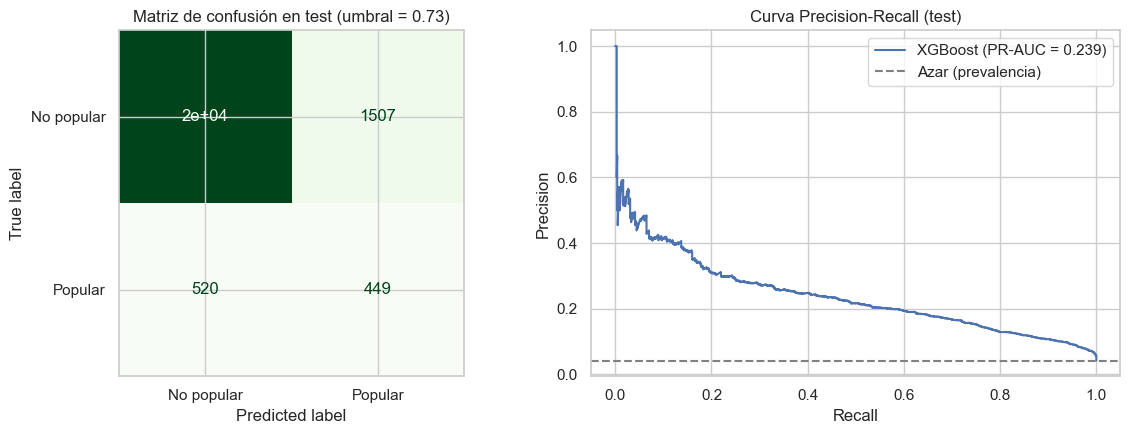

In [12]:
# Matriz de confusión (umbral óptimo) y curva Precision-Recall en test
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

pred_opt = (proba_test >= best_thr).astype(int)
ConfusionMatrixDisplay(confusion_matrix(yc_test, pred_opt),
                       display_labels=["No popular", "Popular"]).plot(ax=ax[0], cmap="Greens", colorbar=False)
ax[0].set_title(f"Matriz de confusión en test (umbral = {best_thr:.2f})")

p, r, _ = precision_recall_curve(yc_test, proba_test)
ax[1].plot(r, p, label=f"XGBoost (PR-AUC = {average_precision_score(yc_test, proba_test):.3f})")
ax[1].axhline(yc_test.mean(), color="gray", ls="--", label="Azar (prevalencia)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Curva Precision-Recall (test)"); ax[1].legend()
plt.tight_layout(); plt.savefig(IMG_DIR / "06_resultados_clasificacion.png", dpi=120); plt.show()

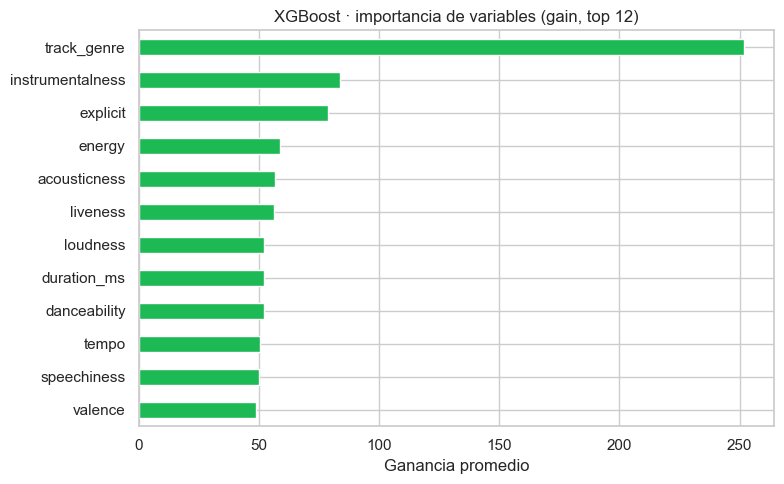

In [13]:
# Importancia de variables según XGBoost (ganancia promedio, top 12)
imp = pd.Series(xgb_clf.get_booster().get_score(importance_type="gain")).sort_values(ascending=True)
imp.tail(12).plot.barh(figsize=(8, 5), color="#1DB954")
plt.title("XGBoost · importancia de variables (gain, top 12)"); plt.xlabel("Ganancia promedio")
plt.tight_layout(); plt.savefig(IMG_DIR / "07_importancia_variables.png", dpi=120); plt.show()

### 6.2 Regresión complementaria (MAE / RMSE)
Mismo algoritmo y mismos conjuntos, pero prediciendo `popularity` (0–100).
Entrega el error promedio en puntos de popularidad, más fácil de comunicar al negocio.

In [14]:
# Línea base de regresión: predecir siempre el promedio de popularity
dummy_reg = DummyRegressor(strategy="mean").fit(X_train, yr_train)

# XGBoost de regresión (misma configuración base que el clasificador)
xgb_reg = XGBRegressor(
    n_estimators=1000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
    eval_metric="rmse", early_stopping_rounds=50, tree_method="hist",
    enable_categorical=True, random_state=SEED, n_jobs=-1,
)
xgb_reg.fit(X_train, yr_train, eval_set=[(X_val, yr_val)], verbose=False)

def metricas_reg(y_true, pred):
    # MAE y RMSE en puntos de popularidad
    return {"MAE": mean_absolute_error(y_true, pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, pred))}

# Tabla de resultados en TEST
tabla_reg = pd.DataFrame({
    "Línea base (promedio)": metricas_reg(yr_test, dummy_reg.predict(X_test)),
    "XGBoost": metricas_reg(yr_test, xgb_reg.predict(X_test)),
}).T
tabla_reg.round(3)

,MAE,RMSE
Línea base (promedio),18.911,22.330
XGBoost,12.269,17.404


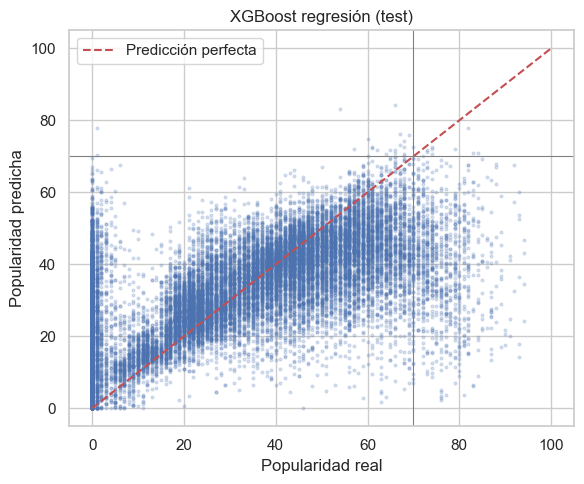

In [15]:
# Popularidad real vs predicha en test (la diagonal roja sería una predicción perfecta)
pred_reg = np.clip(xgb_reg.predict(X_test), 0, 100)
plt.figure(figsize=(6, 5))
plt.scatter(yr_test, pred_reg, s=4, alpha=0.2)
plt.plot([0, 100], [0, 100], "r--", label="Predicción perfecta")
plt.axhline(THRESHOLD_POPULAR, color="gray", lw=0.8); plt.axvline(THRESHOLD_POPULAR, color="gray", lw=0.8)
plt.xlabel("Popularidad real"); plt.ylabel("Popularidad predicha"); plt.title("XGBoost regresión (test)")
plt.legend(); plt.tight_layout(); plt.savefig(IMG_DIR / "08_regresion_real_vs_predicho.png", dpi=120); plt.show()

In [16]:
# Guarda los modelos entrenados en models/ (formato JSON nativo de XGBoost)
xgb_clf.save_model(MODELS_DIR / "xgb_clasificador.json")
xgb_reg.save_model(MODELS_DIR / "xgb_regresor.json")
print("Modelos guardados en:", MODELS_DIR.resolve())

Modelos guardados en: D:\Cosas-Mia\Enginner Data\Semestre 6\ML\Exp_2\Prueba\Spotify\models


## 6.3 Modelo Supervisado 2: Random Forest

Para cumplir con el requisito de comparar múltiples algoritmos supervisados, implementamos **Random Forest**, un método de ensamble basado en árboles de decisión independientes.

**Justificación:** Random Forest ofrece una arquitectura fundamentalmente distinta a XGBoost (bagging vs boosting), permitiendo validar si los patrones aprendidos son consistentes entre enfoques. Además, su robustez ante overfitting y capacidad de manejar variables categóricas nativas lo hace ideal como modelo de comparación.

In [18]:
# ============================================================================
# MODELO SUPERVISADO 2: RANDOM FOREST (Clasificación)
# ============================================================================
# Random Forest de scikit-learn NO soporta variables categóricas nativas
# (a diferencia de XGBoost). Debemos aplicar One-Hot Encoding primero.

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identificar columnas categóricas y numéricas
# track_genre es la única variable categórica que necesita codificación
categorical_cols = ['track_genre']
numeric_cols = [col for col in X_train.columns if col not in categorical_cols]

print(f"Columnas numéricas: {len(numeric_cols)}")
print(f"Columnas categóricas: {len(categorical_cols)} ({categorical_cols})")

# Crear pipeline de preprocesamiento
# OneHotEncoder convierte cada género en una columna binaria (0 o 1)
# sparse_output=False devuelve un array denso (más fácil de manejar)
# handle_unknown='ignore' evita errores si aparecen géneros nuevos en test
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ],
    remainder='passthrough'  # Mantiene las columnas numéricas sin cambios
)

print("\nAplicando One-Hot Encoding...")
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print(f"✓ Datos codificados: {X_train_encoded.shape[1]} columnas totales")
print(f"  - Antes: {len(X_train.columns)} columnas")
print(f"  - Después: {X_train_encoded.shape[1]} columnas (agregadas {X_train_encoded.shape[1] - len(numeric_cols)} categorías de géneros)")

# Configuración del modelo Random Forest
# - n_estimators=500: número de árboles en el bosque
# - max_depth=None: permite árboles profundos para capturar relaciones complejas
# - min_samples_split=5: evita overfitting requiriendo mínimo 5 muestras para dividir
# - class_weight='balanced': compensa automáticamente el desbalance de clases (~4% populares)
# - random_state=SEED: garantiza reproducibilidad
# - n_jobs=-1: usa todos los núcleos disponibles para acelerar el entrenamiento

rf_clf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=SEED,
    n_jobs=-1
)

print("\nEntrenando Random Forest...")
rf_clf.fit(X_train_encoded, yc_train)
print("✓ Entrenamiento completado")

# Generación de predicciones y probabilidades en el conjunto de test
# - predict(): devuelve clases binarias (0 o 1)
# - predict_proba(): devuelve probabilidades para cada clase
rf_pred = rf_clf.predict(X_test_encoded)
rf_proba = rf_clf.predict_proba(X_test_encoded)[:, 1]  # Probabilidad de clase "popular"

print(f"\nPredicciones generadas: {len(rf_pred):,} canciones evaluadas")

Columnas numéricas: 14
Columnas categóricas: 1 (['track_genre'])

Aplicando One-Hot Encoding...
✓ Datos codificados: 128 columnas totales
  - Antes: 15 columnas
  - Después: 128 columnas (agregadas 114 categorías de géneros)

Entrenando Random Forest...
✓ Entrenamiento completado

Predicciones generadas: 22,800 canciones evaluadas


TABLA COMPARATIVA: XGBoost vs Random Forest
  Métrica  XGBoost  Random Forest
Precision 0.229550       0.216606
   Recall 0.463364       0.061920
 F1-Score 0.307009       0.096308
   PR-AUC 0.239391       0.184976

🏆 MEJOR MODELO: XGBoost (F1: 0.3070 vs 0.0963)


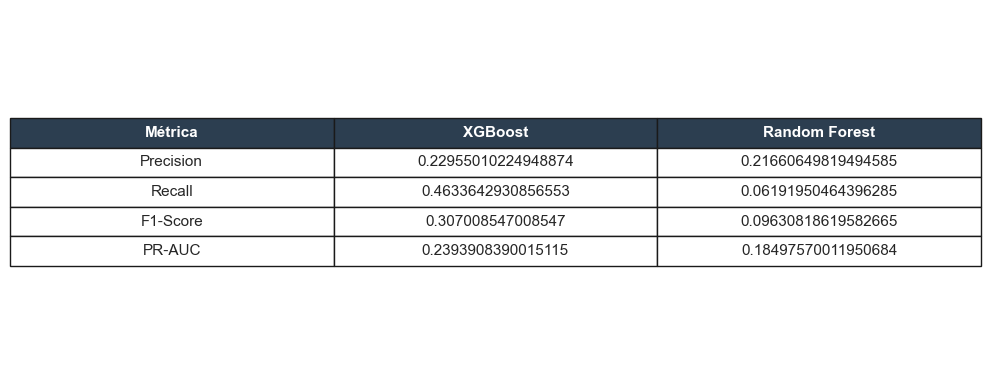


✓ Gráfico guardado: images/09_comparacion_modelos.png


In [24]:
# ============================================================================
# COMPARACIÓN DE MODELOS SUPERVISADOS: XGBoost vs Random Forest
# ============================================================================
# Este código calcula métricas para ambos modelos y genera una tabla comparativa
# usando las mismas funciones de evaluación definidas previamente.

# Calculamos métricas para Random Forest usando umbral óptimo de XGBoost
# (consistencia en la evaluación)
rf_metrics = metricas_clf(yc_test, rf_proba, best_thr)

# Tabla comparativa lado a lado
comparacion = pd.DataFrame({
    "Métrica": ["Precision", "Recall", "F1-Score", "PR-AUC"],
    "XGBoost": [
        metricas_clf(yc_test, proba_test, best_thr)["Precision"],
        metricas_clf(yc_test, proba_test, best_thr)["Recall"],
        metricas_clf(yc_test, proba_test, best_thr)["F1"],
        metricas_clf(yc_test, proba_test, best_thr)["PR-AUC"]
    ],
    "Random Forest": [
        rf_metrics["Precision"],
        rf_metrics["Recall"],
        rf_metrics["F1"],
        rf_metrics["PR-AUC"]
    ]
})

print("=" * 70)
print("TABLA COMPARATIVA: XGBoost vs Random Forest")
print("=" * 70)
print(comparacion.to_string(index=False))
print("=" * 70)

# Análisis automático del ganador
f1_xgb = comparacion.loc[comparacion["Métrica"] == "F1-Score", "XGBoost"].values[0]
f1_rf = comparacion.loc[comparacion["Métrica"] == "F1-Score", "Random Forest"].values[0]

if f1_xgb > f1_rf:
    print(f"\n🏆 MEJOR MODELO: XGBoost (F1: {f1_xgb:.4f} vs {f1_rf:.4f})")
else:
    print(f"\n🏆 MEJOR MODELO: Random Forest (F1: {f1_rf:.4f} vs {f1_xgb:.4f})")

# Guardamos la tabla comparativa como imagen para el informe
fig, ax = plt.subplots(figsize=(10, 4))
ax.axis('tight')
ax.axis('off')
table = ax.table(
    cellText=comparacion.values,
    colLabels=comparacion.columns,
    cellLoc='center',
    loc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.5)

# Colorear encabezados
for i in range(len(comparacion.columns)):
    table[(0, i)].set_facecolor('#2c3e50')
    table[(0, i)].set_text_props(weight='bold', color='white')

plt.tight_layout()
plt.savefig(IMG_DIR / "09_comparacion_modelos.png", dpi=120, bbox_inches='tight')
plt.show()
print("\n✓ Gráfico guardado: images/09_comparacion_modelos.png")

Total de variables codificadas: 128
  - Variables numéricas: 14
  - Variables categóricas (one-hot): 114

TOP 10 VARIABLES MÁS IMPORTANTES (Random Forest):
              Variable  Importancia
    track_genre_techno     0.081854
      track_genre_soul     0.076865
     track_genre_study     0.075878
     track_genre_tango     0.074037
    track_genre_trance     0.071193
       track_genre_ska     0.070849
track_genre_songwriter     0.064183
 track_genre_synth-pop     0.060292
   track_genre_turkish     0.059491
  track_genre_trip-hop     0.058470


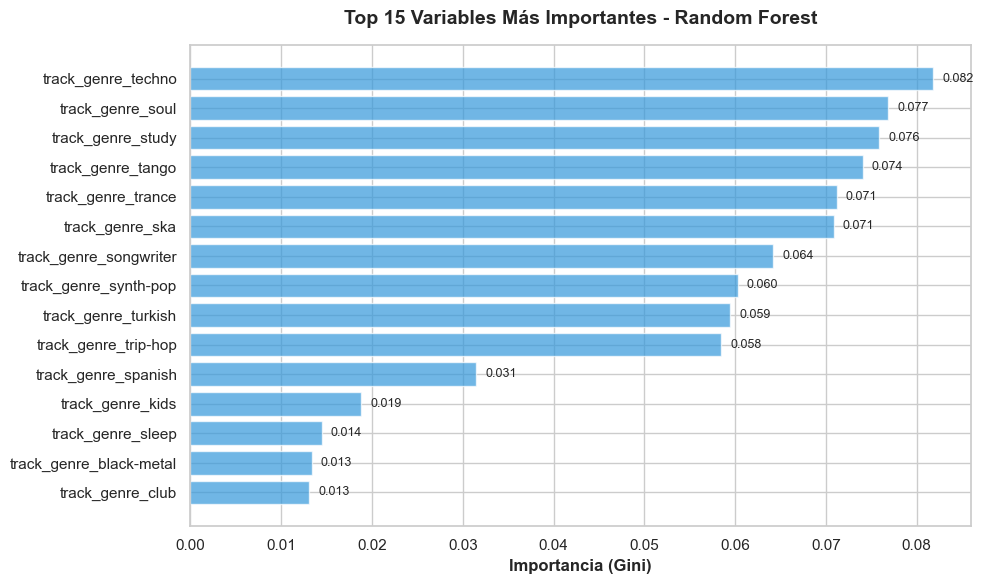


✓ Gráfico guardado: images/10_importancia_rf.png


In [25]:
# ============================================================================
# IMPORTANCIA DE VARIABLES: RANDOM FOREST
# ============================================================================
# Este código extrae y visualiza qué variables de audio son más importantes
# según Random Forest, permitiendo comparar con XGBoost.
# NOTA: Como aplicamos One-Hot Encoding, necesitamos obtener los nombres
# correctos de todas las columnas codificadas.

# Obtener nombres de columnas después del One-Hot Encoding
# El preprocessor ya fue ajustado en la celda anterior
columnas_codificadas = list(preprocessor.transform(X_train).columns) if hasattr(preprocessor.transform(X_train), 'columns') else None

# Si no tiene atributo columns, construir manualmente
if columnas_codificadas is None:
    # Obtener nombres de columnas categóricas codificadas
    cat_encoder = preprocessor.named_transformers_['cat']
    cat_columnas = list(cat_encoder.get_feature_names_out(categorical_cols))
    # Combinar con columnas numéricas
    columnas_codificadas = list(X_train[numeric_cols].columns) + cat_columnas

print(f"Total de variables codificadas: {len(columnas_codificadas)}")
print(f"  - Variables numéricas: {len(numeric_cols)}")
print(f"  - Variables categóricas (one-hot): {len(columnas_codificadas) - len(numeric_cols)}")

# Extracción de importancias (Gini importance)
importancias_rf = pd.DataFrame({
    'Variable': columnas_codificadas,
    'Importancia': rf_clf.feature_importances_
}).sort_values('Importancia', ascending=False)

print("\nTOP 10 VARIABLES MÁS IMPORTANTES (Random Forest):")
print("=" * 50)
print(importancias_rf.head(10).to_string(index=False))

# Visualización comparativa
fig, ax = plt.subplots(figsize=(10, 6))

# Limitar a top 15 para mejor visualización
top_n = 15
top_vars = importancias_rf.head(top_n)

bars = ax.barh(
    range(len(top_vars)), 
    top_vars['Importancia'], 
    color='#3498db',
    alpha=0.7
)

ax.set_yticks(range(len(top_vars)))
ax.set_yticklabels(top_vars['Variable'], fontsize=11)
ax.set_xlabel('Importancia (Gini)', fontsize=12, fontweight='bold')
ax.set_title(f'Top {top_n} Variables Más Importantes - Random Forest', 
             fontsize=14, fontweight='bold', pad=15)
ax.invert_yaxis()  # Invertir para que la más importante esté arriba

# Agregar valores numéricos en las barras
for i, (idx, row) in enumerate(top_vars.iterrows()):
    ax.text(
        row['Importancia'] + 0.001, 
        i, 
        f"{row['Importancia']:.3f}",
        va='center',
        fontsize=9
    )

plt.tight_layout()
plt.savefig(IMG_DIR / "10_importancia_rf.png", dpi=120, bbox_inches='tight')
plt.show()
print(f"\n✓ Gráfico guardado: images/10_importancia_rf.png")

## 6.4 Análisis No Supervisado: Clustering de Canciones

Aplicamos **K-Means** para descubrir patrones ocultos en las características de audio, sin usar la variable de popularidad. El objetivo es identificar "perfiles musicales" o grupos naturales de canciones.

**Justificación:** El clustering permite segmentar el catálogo musical en categorías objetivas basadas en características acústicas, revelando fórmulas de éxito y oportunidades de diversificación que el análisis supervisado no captura directamente.

In [26]:
# ============================================================================
# PREPARACIÓN DE DATOS PARA CLUSTERING
# ============================================================================
# Este código prepara un subconjunto de variables numéricas de audio para
# el algoritmo K-Means, excluyendo variables categóricas y el target.

from sklearn.preprocessing import StandardScaler

# Selección de variables numéricas de audio para clustering
# Excluimos: track_id, nombres, variables categóricas (track_genre, key, mode)
# y la variable objetivo (popularity, is_popular)
variables_clustering = [
    'danceability', 'energy', 'loudness', 'speechiness', 
    'acousticness', 'instrumentalness', 'liveness', 'valence',
    'tempo', 'duration_ms', 'time_signature'
]

# Filtrar solo columnas que existen en el dataset
variables_clustering = [v for v in variables_clustering if v in df.columns]

print(f"Variables seleccionadas para clustering: {len(variables_clustering)}")
print(variables_clustering)

# Extraer datos para clustering (usamos TODO el dataset, no solo train/test)
X_clustering = df[variables_clustering].copy()

# Manejo de valores nulos (si existen)
nulos_antes = X_clustering.isna().sum().sum()
print(f"\nValores nulos antes de limpieza: {nulos_antes}")

# Rellenar nulos con medianas (método robusto ante outliers)
X_clustering = X_clustering.fillna(X_clustering.median())

# Estandarización (CRÍTICO para K-Means)
# K-Means usa distancias euclidianas, por lo que todas las variables deben
# estar en la misma escala para que ninguna domine el clustering
scaler = StandardScaler()
X_clustering_scaled = scaler.fit_transform(X_clustering)

print(f"✓ Datos escalados: {X_clustering_scaled.shape[0]:,} canciones × {X_clustering_scaled.shape[1]} variables")

Variables seleccionadas para clustering: 11
['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'time_signature']

Valores nulos antes de limpieza: 0
✓ Datos escalados: 114,000 canciones × 11 variables


Calculando inercia y silueta para diferentes valores de K...
K= 2 | Inercia =   1,027,729.73 | Silueta = 0.2532
K= 3 | Inercia =     933,955.96 | Silueta = 0.1433
K= 4 | Inercia =     868,973.45 | Silueta = 0.1464
K= 5 | Inercia =     801,562.12 | Silueta = 0.1532
K= 6 | Inercia =     748,584.66 | Silueta = 0.1587
K= 7 | Inercia =     699,083.90 | Silueta = 0.1637
K= 8 | Inercia =     654,820.33 | Silueta = 0.1710
K= 9 | Inercia =     626,812.16 | Silueta = 0.1717
K=10 | Inercia =     598,785.95 | Silueta = 0.1712

✓ K sugerido por el método del codo: 5
✓ K con mejor silueta: 2


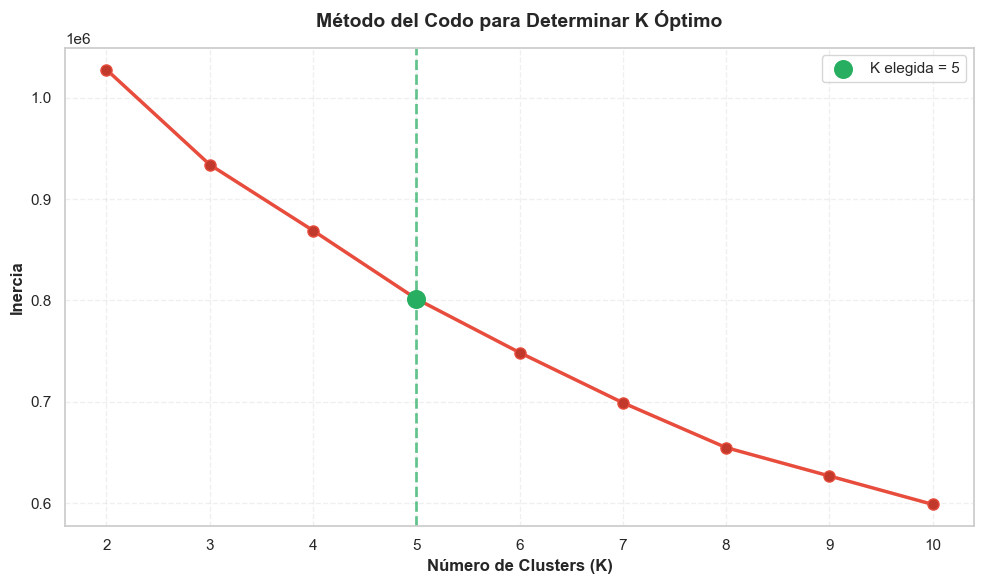


✓ Gráfico guardado: images/11_metodo_codo.png


In [29]:
# ============================================================================
# MÉTODO DEL CODO: DETERMINACIÓN DEL NÚMERO ÓPTIMO DE CLUSTERS
# ============================================================================
# Evalúa distintos valores de K y compara dos criterios:
#   1) Inercia  -> método del codo (punto donde deja de mejorar mucho).
#   2) Silueta  -> qué tan separado y compacto está cada cluster.
# IMPORTANTE: KMeans NO acepta el parámetro n_jobs.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Rango de soluciones a evaluar
k_range = list(range(2, 11))
inercias, siluetas = [], []

print("Calculando inercia y silueta para diferentes valores de K...")
print("=" * 62)

# Tamaño de muestra para calcular la silueta (hasta 10.000 canciones)
n_muestra = min(10_000, X_clustering_scaled.shape[0])

# Generar índices de muestra UNA sola vez (misma muestra para todos los K,
# así la comparación de siluetas es justa)
rng = np.random.RandomState(SEED)
muestra = rng.choice(
    X_clustering_scaled.shape[0],
    size=n_muestra,
    replace=False
)

for k in k_range:
    # init='k-means++': inicializa los centroides separados entre sí
    # n_init=10: repite el ajuste con 10 inicializaciones y se queda con la mejor
    # max_iter=300: límite de iteraciones para garantizar convergencia
    # random_state=SEED: resultados reproducibles
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        max_iter=300,
        random_state=SEED
    )

    etiquetas = kmeans.fit_predict(X_clustering_scaled)
    inercias.append(kmeans.inertia_)

    # Calcular silueta solo sobre la muestra (más rápido)
    silueta = silhouette_score(
        X_clustering_scaled[muestra],
        etiquetas[muestra]
    )
    siluetas.append(silueta)

    print(f"K={k:2d} | Inercia = {kmeans.inertia_:>14,.2f} | Silueta = {silueta:.4f}")

# ---------------------------------------------------------------------------
# Detección automática del codo
# ---------------------------------------------------------------------------
# Se normalizan K y la inercia a [0, 1] y se mide la distancia de cada punto
# a la recta que une el primer y último punto. El punto más lejano es el codo.
x = np.array(k_range, dtype=float)
y = np.array(inercias, dtype=float)

x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (y - y.min()) / (y.max() - y.min() + 1e-12)

distancia_a_recta = np.abs(y_norm - (1 - x_norm))
codo_k = int(x[np.argmax(distancia_a_recta)])

print(f"\n✓ K sugerido por el método del codo: {codo_k}")
print(f"✓ K con mejor silueta: {k_range[int(np.argmax(siluetas))]}")

# ---------------------------------------------------------------------------
# Gráfico del codo con la K seleccionada
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    k_range, inercias,
    marker='o', linewidth=2.5, markersize=8,
    color='#e74c3c', markerfacecolor='#c0392b'
)
ax.axvline(x=codo_k, color='#27ae60', linestyle='--', linewidth=2, alpha=0.7)
ax.scatter([codo_k], [inercias[k_range.index(codo_k)]],
           color='#27ae60', s=160, zorder=5, label=f'K elegida = {codo_k}')

ax.set_xlabel('Número de Clusters (K)', fontsize=12, fontweight='bold')
ax.set_ylabel('Inercia', fontsize=12, fontweight='bold')
ax.set_title('Método del Codo para Determinar K Óptimo',
             fontsize=14, fontweight='bold', pad=15)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xticks(k_range)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig(IMG_DIR / "11_metodo_codo.png", dpi=120, bbox_inches='tight')
plt.show()

print(f"\n✓ Gráfico guardado: images/11_metodo_codo.png")

Aplicando K-Means con K=5 clusters...
✓ 114,000 canciones asignadas a 5 clusters

Distribución de canciones por cluster:
Cluster 0: 8,377 canciones (7.3%)
Cluster 1: 42,319 canciones (37.1%)
Cluster 2: 24,608 canciones (21.6%)
Cluster 3: 8,043 canciones (7.1%)
Cluster 4: 30,653 canciones (26.9%)

PERFIL DE CADA CLUSTER (Promedio de características de audio)
         danceability  energy  acousticness  valence    tempo
cluster                                                      
0               0.531   0.748         0.344    0.500  121.233
1               0.689   0.736         0.187    0.682  120.695
2               0.543   0.387         0.668    0.406  113.584
3               0.351   0.185         0.839    0.183  103.577
4               0.483   0.806         0.063    0.311  136.151

POPULARIDAD POR CLUSTER
         % Populares  Total Populares  Popularidad Promedio
cluster                                                    
0                1.5              123                34.145
1

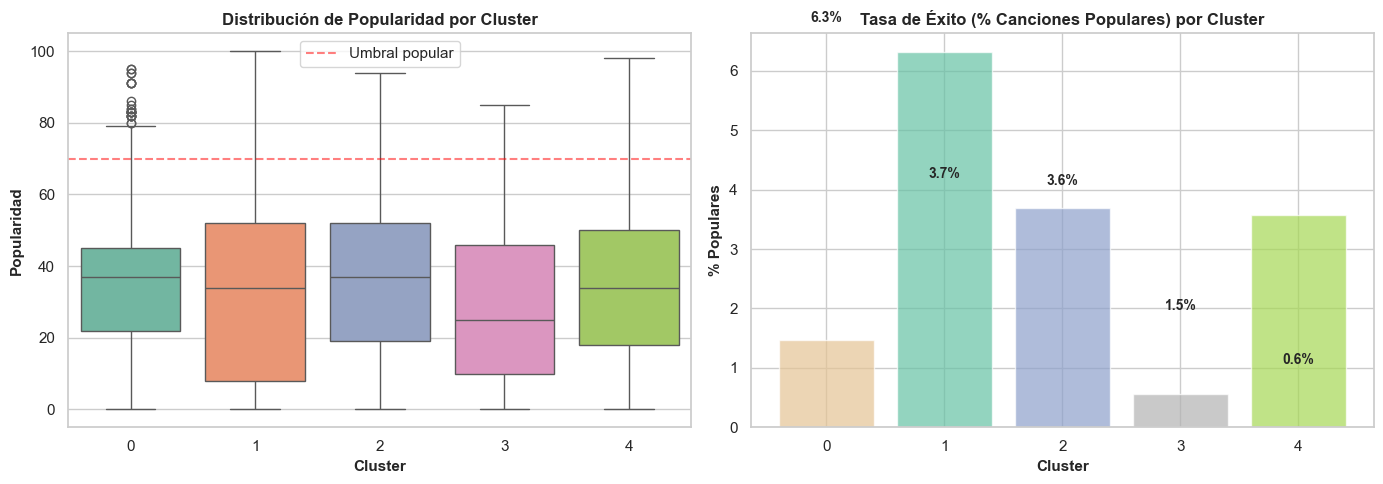


✓ Gráfico guardado: images/12_analisis_clusters.png


In [33]:
# ============================================================================
# CLUSTERING FINAL Y ANÁLISIS DE PERFILES MUSICALES
# ============================================================================
# Aplica K-Means con el número óptimo de clusters y analiza las características
# de cada grupo para identificar patrones de negocio.
# IMPORTANTE: KMeans NO acepta n_jobs. Se usa codo_k del método del codo.

# Número de clusters: se toma automáticamente del método del codo
K_OPTIMO = codo_k  # NO fijar a mano; viene de la celda anterior

print(f"Aplicando K-Means con K={K_OPTIMO} clusters...")

# KMeans SIN n_jobs (ese parámetro no existe en este estimador)
kmeans_final = KMeans(
    n_clusters=K_OPTIMO,
    init='k-means++',
    n_init=10,
    max_iter=300,
    random_state=SEED
)

# Asignar cada canción a un cluster
# X_clustering_scaled es un numpy array, cluster_labels también lo será
cluster_labels = kmeans_final.fit_predict(X_clustering_scaled)

# Asignar al DataFrame original
# IMPORTANTE: asegurar que la longitud coincide
assert len(cluster_labels) == len(df), \
    f"Error: cluster_labels tiene {len(cluster_labels)} elementos pero df tiene {len(df)} filas"

df['cluster'] = cluster_labels

print(f"✓ {len(df):,} canciones asignadas a {K_OPTIMO} clusters")

# Análisis de distribución de clusters
distribucion_clusters = df['cluster'].value_counts().sort_index()
print("\nDistribución de canciones por cluster:")
print("=" * 50)
for cluster, count in distribucion_clusters.items():
    pct = count / len(df) * 100
    print(f"Cluster {cluster}: {count:,} canciones ({pct:.1f}%)")

# Caracterización de cada cluster (promedio de variables por cluster)
perfil_clusters = df.groupby('cluster')[variables_clustering].mean()

print("\n" + "=" * 70)
print("PERFIL DE CADA CLUSTER (Promedio de características de audio)")
print("=" * 70)

# Mostrar variables más distintivas
variables_clave = ['danceability', 'energy', 'acousticness', 'valence', 'tempo']
print(perfil_clusters[variables_clave].round(3).to_string())

# Análisis de popularidad por cluster
print("\n" + "=" * 70)
print("POPULARIDAD POR CLUSTER")
print("=" * 70)

pop_por_cluster = df.groupby('cluster').agg({
    'is_popular': ['mean', 'sum'],
    'popularity': 'mean'
}).round(3)

# Aplanar el MultiIndex de columnas
pop_por_cluster.columns = ['% Populares', 'Total Populares', 'Popularidad Promedio']
pop_por_cluster['% Populares'] = (pop_por_cluster['% Populares'] * 100).round(2)

print(pop_por_cluster.to_string())

# Visualización: Popularidad vs Cluster
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Distribución de popularidad por cluster
sns.boxplot(
    data=df,
    x='cluster',
    y='popularity',
    palette='Set2',
    ax=axes[0]
)
axes[0].set_title('Distribución de Popularidad por Cluster',
                   fontsize=12, fontweight='bold')
axes[0].set_xlabel('Cluster', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Popularidad', fontsize=11, fontweight='bold')
axes[0].axhline(y=70, color='red', linestyle='--', alpha=0.5, label='Umbral popular')
axes[0].legend()

# Gráfico 2: Tasa de éxito por cluster
tasas_exito = (df.groupby('cluster')['is_popular']
                .mean()
                .sort_values(ascending=False) * 100)

# Generar colores dinámicamente según el número de clusters
colores = plt.cm.Set2(np.linspace(0, 1, len(tasas_exito)))

axes[1].bar(
    tasas_exito.index,
    tasas_exito.values,
    color=colores,
    alpha=0.7
)

axes[1].set_title('Tasa de Éxito (% Canciones Populares) por Cluster',
                   fontsize=12, fontweight='bold')
axes[1].set_xlabel('Cluster', fontsize=11, fontweight='bold')
axes[1].set_ylabel('% Populares', fontsize=11, fontweight='bold')
axes[1].set_xticks(tasas_exito.index)

# Agregar etiquetas de porcentaje
for i, (cluster, tasa) in enumerate(tasas_exito.items()):
    axes[1].text(
        i,
        tasa + 0.5,
        f'{tasa:.1f}%',
        ha='center',
        fontweight='bold',
        fontsize=10
    )

plt.tight_layout()
plt.savefig(IMG_DIR / "12_analisis_clusters.png", dpi=120, bbox_inches='tight')
plt.show()
print(f"\n✓ Gráfico guardado: images/12_analisis_clusters.png")

In [34]:
# ============================================================================
# CARACTERIZACIÓN DETALLADA: ¿QUÉ DEFINE A CADA CLUSTER?
# ============================================================================
# Genera descripciones automáticas de cada cluster comparando sus valores
# contra el promedio global del dataset. Solo usa variables de escala 0-1
# para determinar rasgos "altos" o "bajos", ya que tempo, duración y
# loudness tienen escalas distintas y distorsionarían la comparación.

print("=" * 70)
print("INTERPRETACIÓN DE CLUSTERS: PERFILES MUSICALES")
print("=" * 70)

# Separar variables por escala para no mezclar peras con manzanas
# Variables de 0 a 1 (comparables entre sí)
vars_01 = ['danceability', 'energy', 'speechiness', 'acousticness',
           'instrumentalness', 'liveness', 'valence']

# Variables con otras escalas (se muestran como contexto)
vars_contexto = ['tempo', 'duration_ms', 'loudness', 'time_signature']

# Promedio global para comparar
perfil_global = df[vars_01].mean()

for cluster_id in range(K_OPTIMO):
    perfil = perfil_clusters.loc[cluster_id, vars_01]

    # Diferencia contra el promedio global (rasgos distintivos)
    diferencia = perfil - perfil_global

    # Top 3 rasgos por encima del promedio y top 3 por debajo
    top_altas = diferencia.nlargest(3)
    top_bajas = diferencia.nsmallest(3)

    # Estadísticas de popularidad
    cluster_data = df[df['cluster'] == cluster_id]
    n_canciones = len(cluster_data)
    pct_populares = cluster_data['is_popular'].mean() * 100
    pop_promedio = cluster_data['popularity'].mean()

    print(f"\n🎵 CLUSTER {cluster_id}")
    print("-" * 70)
    print(f"Tamaño: {n_canciones:,} canciones ({n_canciones/len(df)*100:.1f}% del total)")
    print(f"Tasa de éxito: {pct_populares:.2f}% populares | Popularidad promedio: {pop_promedio:.1f}")

    print(f"\n🔝 Rasgos por ENCIMA del promedio global:")
    for var, diff in top_altas.items():
        valor_cluster = perfil[var]
        valor_global = perfil_global[var]
        print(f"   • {var}: {valor_cluster:.3f} (global: {valor_global:.3f}, dif: {diff:+.3f})")

    print(f"\n🔻 Rasgos por DEBAJO del promedio global:")
    for var, diff in top_bajas.items():
        valor_cluster = perfil[var]
        valor_global = perfil_global[var]
        print(f"   • {var}: {valor_cluster:.3f} (global: {valor_global:.3f}, dif: {diff:+.3f})")

    print(f"\n📊 Contexto adicional:")
    for var in vars_contexto:
        if var in perfil_clusters.columns:
            valor = perfil_clusters.loc[cluster_id, var]
            if var == 'duration_ms':
                print(f"   • Duración promedio: {valor/60000:.1f} min")
            elif var == 'tempo':
                print(f"   • Tempo promedio: {valor:.1f} BPM")
            elif var == 'loudness':
                print(f"   • Loudness promedio: {valor:.1f} dB")
            else:
                print(f"   • {var}: {valor:.1f}")

    # Generar etiqueta descriptiva automática
    if perfil['energy'] > 0.7 and perfil['danceability'] > 0.7:
        etiqueta = "Alta Energía / Bailable"
    elif perfil['acousticness'] > 0.5 and perfil['energy'] < 0.4:
        etiqueta = "Acústico / Relajante"
    elif perfil['valence'] < 0.3:
        etiqueta = "Melancólico / Serio"
    elif perfil['valence'] > 0.7 and perfil['tempo'] > 120:
        etiqueta = "Alegre / Rápido"
    else:
        etiqueta = "Balanceado / Estándar"

    print(f"\n💡 Etiqueta sugerida: '{etiqueta}'")
    print("=" * 70)

INTERPRETACIÓN DE CLUSTERS: PERFILES MUSICALES

🎵 CLUSTER 0
----------------------------------------------------------------------
Tamaño: 8,377 canciones (7.3% del total)
Tasa de éxito: 1.47% populares | Popularidad promedio: 34.1

🔝 Rasgos por ENCIMA del promedio global:
   • liveness: 0.738 (global: 0.214, dif: +0.525)
   • speechiness: 0.194 (global: 0.085, dif: +0.109)
   • energy: 0.748 (global: 0.641, dif: +0.107)

🔻 Rasgos por DEBAJO del promedio global:
   • instrumentalness: 0.061 (global: 0.156, dif: -0.095)
   • danceability: 0.531 (global: 0.567, dif: -0.036)
   • valence: 0.500 (global: 0.474, dif: +0.026)

📊 Contexto adicional:
   • Tempo promedio: 121.2 BPM
   • Duración promedio: 3.9 min
   • Loudness promedio: -7.5 dB
   • time_signature: 3.9

💡 Etiqueta sugerida: 'Balanceado / Estándar'

🎵 CLUSTER 1
----------------------------------------------------------------------
Tamaño: 42,319 canciones (37.1% del total)
Tasa de éxito: 6.32% populares | Popularidad promedio: 3

## 7. Interpretación de resultados

> **Completar tras ejecutar el notebook**, con los números de las tablas anteriores:
> 1. ¿El F1 y el PR-AUC superan a la línea base y a la prevalencia (~4 %)?
> 2. Qué significan Precision y Recall con el umbral elegido (ej.: "de cada 100 canciones recomendadas, X son realmente populares").
> 3. El MAE/RMSE en puntos de popularidad, comparado con la distancia al umbral de 70.
> 4. Qué variables pesan más y si tienen sentido para el negocio.